# 04 · Strategy research — can anything beat Buy & Hold? (development period)

Follow-up question: *is there a model or strategy whose return beats Buy & Hold SPY?*

The original test period (2023–2024) has already been used, so it can no longer select anything. The protocol is fixed in **[`outputs/research/preregistration.md`](../outputs/research/preregistration.md)**, written (and hashed) before this notebook was run:

- **Development = walk-forward 2013–2022.** Each year is predicted by models refit on all earlier data whose labels were known before 1 January of that year. This covers several regimes: the 2015–16 correction, the 2018 sell-off, the 2020 crash and the 2022 bear market. It is the only data used to pick a strategy.
- 2023–2024 is shown as **secondary, already-seen** evidence.
- The **fresh holdout (2025 → latest)** is evaluated in `05_holdout_2025.ipynb`.

Candidates (parameters fixed in advance): S0 Buy & Hold · S1 SMA200 trend filter · S2 frozen RF, default-long · S3 drop-risk classifier · S4/S5 volatility targeting (trailing / ML-forecast vol) · S4L/S5L/S6L levered (≤ 1.5×, 5% borrow cost) versions.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score

from src import config
from src.data import load_snapshot
from src.research import research_dataset, build_candidates, evaluate

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
RES = config.OUTPUT_DIR / "research"; RES.mkdir(exist_ok=True)
def savefig(name): plt.savefig(config.FIG_DIR / f"research_{name}.png", dpi=120, bbox_inches="tight")

raw = load_snapshot()                  # original snapshot: ends 2024-12-31, no 2025+ data here
prices = raw[["Open", "Close"]]
ds = research_dataset(raw)
print("data:", ds.index.min().date(), "→", ds.index.max().date())
print("drop10 base rate (2006-2012):", round(ds.loc["2006":"2012", "drop10"].mean(), 3))

data: 2005-10-17 → 2024-12-31
drop10 base rate (2006-2012): 0.147


## 1. Walk-forward signals (yearly refits) and backtests

In [2]:
weights, diag = build_candidates(ds, years=range(2013, 2025))
DEV, SEEN = ("2013-01-01", "2022-12-31"), ("2023-01-01", "2024-12-31")

def run_period(period):
    rows, values = [], {}
    for name, w in weights.items():
        m, v = evaluate(w.loc[period[0]:period[1]], prices, name)
        rows.append(m); values[name] = v
    return pd.DataFrame(rows).set_index("strategy"), pd.DataFrame(values)

dev, dev_values = run_period(DEV)
dev

,total_return,cagr,ann_vol,sharpe,max_drawdown,calmar,n_orders,avg_exposure,total_fees,final_value
strategy,,,,,,,,,,
S0 Buy & Hold,2.1493,0.1217,0.1737,0.7480,-0.3372,0.3610,1,1.0000,99.9000,314933.5700
S1 Trend SMA200,1.2096,0.0826,0.1163,0.7410,-0.2001,0.4130,50,0.8260,8898.0600,220959.0900
S2 RF default-long,1.2065,0.0824,0.1647,0.5640,-0.3125,0.2640,89,0.9530,15580.3000,220654.1200
S3 Drop-risk LR,1.1158,0.0779,0.1484,0.5800,-0.2553,0.3050,117,0.9070,21163.6000,211579.3100
S4 Vol-target σ20,1.8095,0.1089,0.1258,0.8850,-0.1781,0.6110,89,0.8940,2948.7900,280952.2700
S5 Vol-target ML,1.6050,0.1006,0.1310,0.7970,-0.2230,0.4510,143,0.9210,5602.0300,260504.6500
S4L Vol-target σ20 ×1.5,1.8385,0.1101,0.1521,0.7630,-0.1821,0.6040,292,1.1620,8848.5300,283847.0700
S5L Vol-target ML ×1.5,1.2926,0.0866,0.1510,0.6260,-0.2438,0.3550,728,1.1630,20905.2100,229256.6000
S6L Trend + Vol-target ML ×1.5,0.8298,0.0623,0.1320,0.5250,-0.2369,0.2630,666,1.0410,21920.0900,182982.5400


## 2. Apply the pre-registered selection rule
Eligible = after-cost CAGR above Buy & Hold over 2013–2022; pick = highest Sharpe among eligible.

In [3]:
bh = dev.loc["S0 Buy & Hold"]
dev["beats_BH_cagr"] = dev["cagr"] > bh["cagr"]
dev["levered"] = dev.index.str.contains("×1.5")
display(dev[["cagr", "sharpe", "max_drawdown", "avg_exposure", "n_orders", "total_fees", "beats_BH_cagr", "levered"]]
        .sort_values("cagr", ascending=False))
eligible = dev[dev["beats_BH_cagr"]]
PICK = eligible["sharpe"].idxmax() if len(eligible) else None
unlev = dev[~dev["levered"] & dev["beats_BH_cagr"]]
print("Eligible:", list(eligible.index))
print("Pre-registered pick:", PICK)
print("Unlevered strategies beating B&H CAGR:", list(unlev.index) or "none")

,cagr,sharpe,max_drawdown,avg_exposure,n_orders,total_fees,beats_BH_cagr,levered
strategy,,,,,,,,
S0 Buy & Hold,0.1217,0.7480,-0.3372,1.0000,1,99.9000,False,False
S4L Vol-target σ20 ×1.5,0.1101,0.7630,-0.1821,1.1620,292,8848.5300,False,True
S4 Vol-target σ20,0.1089,0.8850,-0.1781,0.8940,89,2948.7900,False,False
S5 Vol-target ML,0.1006,0.7970,-0.2230,0.9210,143,5602.0300,False,False
S5L Vol-target ML ×1.5,0.0866,0.6260,-0.2438,1.1630,728,20905.2100,False,True
S1 Trend SMA200,0.0826,0.7410,-0.2001,0.8260,50,8898.0600,False,False
S2 RF default-long,0.0824,0.5640,-0.3125,0.9530,89,15580.3000,False,False
S3 Drop-risk LR,0.0779,0.5800,-0.2553,0.9070,117,21163.6000,False,False
S6L Trend + Vol-target ML ×1.5,0.0623,0.5250,-0.2369,1.0410,666,21920.0900,False,True


Eligible: []
Pre-registered pick: None
Unlevered strategies beating B&H CAGR: none


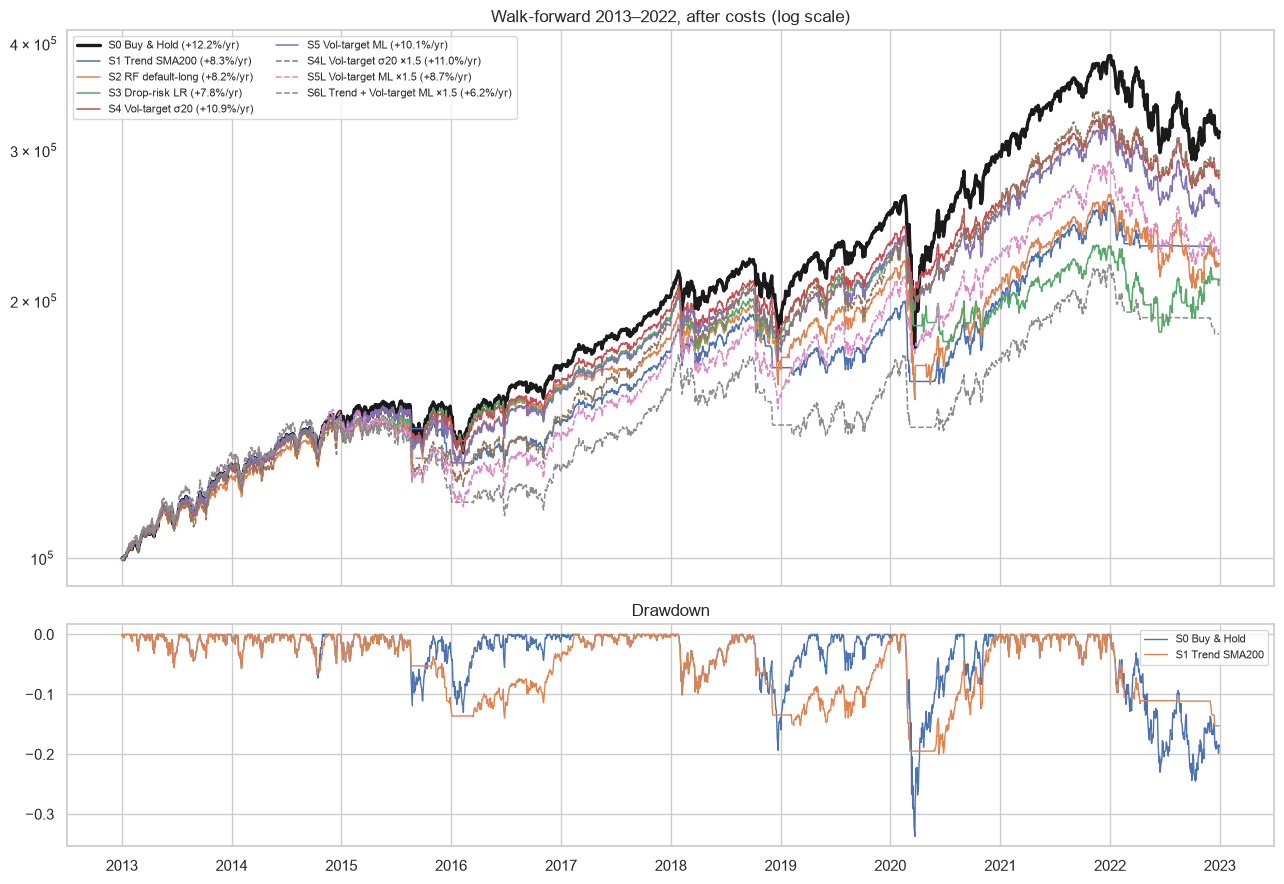

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(13, 9), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
for name in dev_values:
    lw, ls = (2.4, "-") if name in ("S0 Buy & Hold", PICK) else (1.1, "--" if "×1.5" in name else "-")
    color = "k" if name == "S0 Buy & Hold" else None
    ax[0].plot(dev_values[name], label=f"{name} ({dev.loc[name, 'cagr']:+.1%}/yr)", lw=lw, ls=ls, color=color)
ax[0].set_yscale("log"); ax[0].legend(fontsize=8, ncol=2); ax[0].set_title("Walk-forward 2013–2022, after costs (log scale)")
for name in ["S0 Buy & Hold", PICK, "S1 Trend SMA200"]:
    if name:
        v = dev_values[name]; ax[1].plot(v / v.cummax() - 1, label=name, lw=1)
ax[1].set_title("Drawdown"); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig("dev_equity"); plt.show()

**Reading — development 2013–2022 (after costs).**
- **No candidate beat Buy & Hold's 12.2%/yr**, so the pre-registered rule produces **no pick**. Even the levered S4L (average exposure 1.16×) reached only 11.0%/yr.
- The robust improvement is in **risk, not return**. S4 (trailing-vol targeting) earns 10.9%/yr with Sharpe **0.89 vs 0.75** and max drawdown **−17.8% vs −33.7%**. The SMA200 trend filter cuts max drawdown to −20.0% but costs ≈ 4 pp per year.
- The ML direction/crash signals (S2, S3) are the weakest unlevered strategies: 7.8–8.2%/yr, plus USD 15–21k in costs from frequent switching.
- Leverage did not rescue returns. Volatility targeting adds leverage in calm periods and removes it right after shocks, which is exactly before rebounds. Each extra trade costs fees, and borrowing costs 5%.

## 3. When does each strategy win? Calendar-year returns (2013–2022)

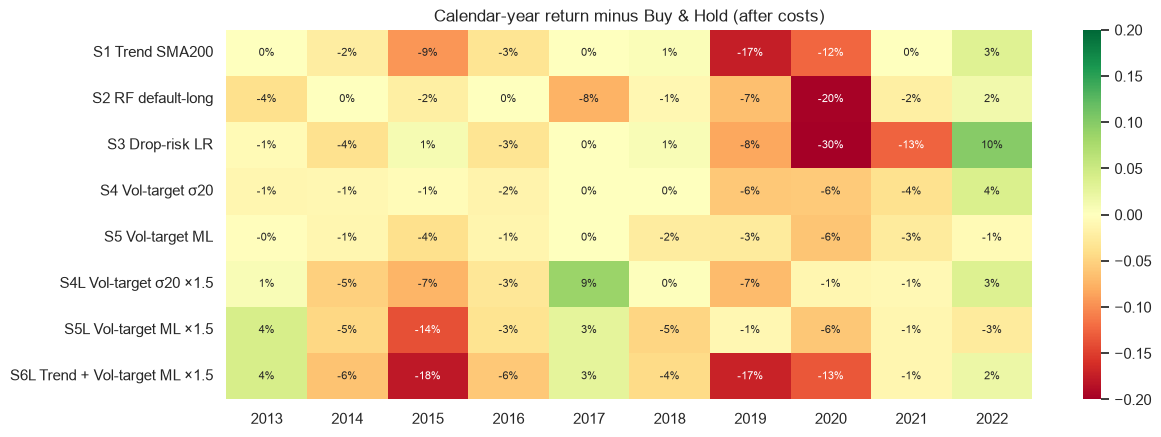

,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
S0 Buy & Hold,0.2887,0.1346,0.0123,0.1200,0.2171,-0.0457,0.3122,0.1833,0.2873,-0.1818


In [5]:
yr = dev_values.resample("YE").last()
start = pd.DataFrame([[config.INIT_CASH] * yr.shape[1]], columns=yr.columns, index=[pd.Timestamp("2012-12-31")])
yearly = pd.concat([start, yr]).pct_change().dropna()
yearly.index = yearly.index.year
excess = yearly.sub(yearly["S0 Buy & Hold"], axis=0).drop(columns="S0 Buy & Hold")
plt.figure(figsize=(13, 4.8))
sns.heatmap(excess.T, annot=True, fmt=".0%", cmap="RdYlGn", center=0, vmin=-0.2, vmax=0.2, annot_kws={"size": 8})
plt.title("Calendar-year return minus Buy & Hold (after costs)"); savefig("dev_yearly_excess"); plt.show()
yearly[["S0 Buy & Hold"]].T

**Reading.** The timing strategies win almost only in **2022, a slow bear market** (S3 +10 pp, S4 +4 pp, S1 +3 pp). They lose most in **V-shaped years**:
- **2019**, after the Q4-2018 sell-off: S1 −17 pp.
- **2020**, the COVID crash and fast recovery: S3 −30 pp, S2 −20 pp, S1 −12 pp.

The best days of the market cluster right after the worst ones. A strategy that de-risks after a fall misses the rebound, so the payoff is asymmetric: a little saved in declines, a lot lost in recoveries. With an upward-drifting index, the recoveries win over a decade.

## 4. Is volatility really predictable? (out-of-sample, 2013–2022)

{'trailing σ20 (naive)': 0.084, 'ML forecast σ̂': 0.344} | corr(ML, realised): 0.6


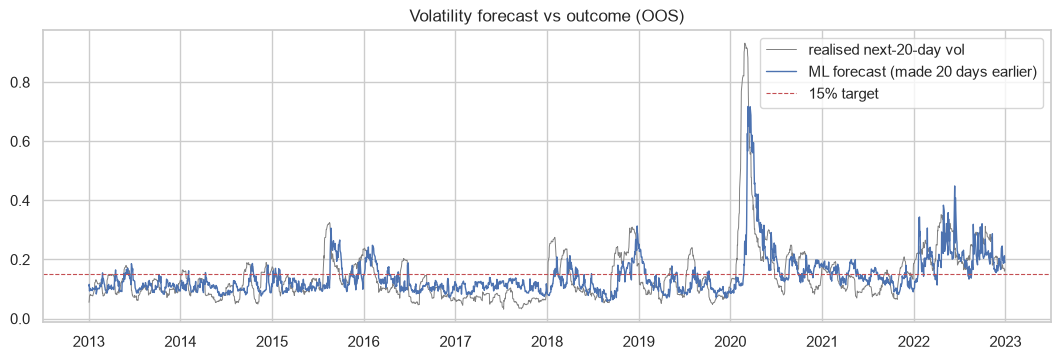

In [6]:
d = diag.loc[DEV[0]:DEV[1]].dropna()
y = np.log(d["fvol20"])
r2 = {"trailing σ20 (naive)": r2_score(y, np.log(d["sigma20"])),
      "ML forecast σ̂": r2_score(y, np.log(d["sigma_ml"]))}
print({k: round(v, 3) for k, v in r2.items()}, "| corr(ML, realised):", round(np.corrcoef(np.log(d["sigma_ml"]), y)[0, 1], 3))
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(d["fvol20"], lw=0.7, label="realised next-20-day vol", color="grey")
ax.plot(d["sigma_ml"], lw=1, label="ML forecast (made 20 days earlier)")
ax.axhline(0.15, color="r", ls="--", lw=0.8, label="15% target")
ax.legend(); ax.set_title("Volatility forecast vs outcome (OOS)"); savefig("vol_forecast"); plt.show()

**Reading.** Volatility *is* predictable. The ML forecast explains **34%** of the variance of log next-20-day volatility out of sample, against 8% for trailing σ20, with a correlation of 0.60 with the outcome. This confirms the main project finding: there is a signal, but it concerns the *size* of moves, not their direction.

Better forecasts did **not** produce a better strategy: S5 (ML) got 10.1%/yr and Sharpe 0.80, versus 10.9%/yr and 0.89 for S4 (trailing). Accuracy on a statistical target is not the same as trading value. The ML forecasts also moved the weight more often (143 vs 89 orders).

## 5. Secondary: 2023–2024 (already seen — not used for any choice)

In [7]:
seen, seen_values = run_period(SEEN)
seen[["total_return", "cagr", "sharpe", "max_drawdown", "avg_exposure", "n_orders", "total_fees"]]

,total_return,cagr,sharpe,max_drawdown,avg_exposure,n_orders,total_fees
strategy,,,,,,,
S0 Buy & Hold,0.5703,0.2543,1.8350,-0.0997,0.9980,1,99.9000
S1 Trend SMA200,0.3925,0.1808,1.4080,-0.0947,0.9660,9,870.7500
S2 RF default-long,0.6369,0.2807,2.0870,-0.0985,0.9620,21,2611.3600
S3 Drop-risk LR,0.4366,0.1995,1.5130,-0.0997,0.9540,15,1819.8400
S4 Vol-target σ20,0.5096,0.2297,1.7350,-0.0997,0.9710,8,222.9000
S5 Vol-target ML,0.5040,0.2274,1.7500,-0.0961,0.9560,17,435.2700
S4L Vol-target σ20 ×1.5,0.5528,0.2472,1.5240,-0.1312,1.2220,78,1561.9800
S5L Vol-target ML ×1.5,0.4983,0.2250,1.4530,-0.1186,1.1560,159,3234.5900
S6L Trend + Vol-target ML ×1.5,0.3653,0.1692,1.1530,-0.1076,1.1310,160,3577.4500


In [8]:
out = {"dev_2013_2022": dev.reset_index().to_dict(orient="records"),
       "seen_2023_2024": seen.reset_index().to_dict(orient="records"),
       "pick": PICK, "vol_r2_dev": r2}
(RES / "dev_results.json").write_text(json.dumps(out, indent=2, default=str))
print("saved outputs/research/dev_results.json")

saved outputs/research/dev_results.json


**Reading — 2023–2024 (already seen, not used for selection).** Here **S2 "RF default-long" beats Buy & Hold**: +63.7% vs +57.0%, Sharpe 2.09 vs 1.84. Choosing a strategy from this period would have picked S2. Yet over 2013–2022 S2 was one of the worst candidates (8.2%/yr vs 12.2%).

This is a concrete example of why the already-used test period cannot select models: a two-year window can make a weak strategy look like a winner. The fresh holdout (`05_holdout_2025.ipynb`) decides how all candidates behave on unseen data.